In [1]:
pip install lightgbm


Note: you may need to restart the kernel to use updated packages.


/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:00<00:00, 135MB/s] 


Training LightGBM model...
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[55]	train's multi_logloss: 0.0062036	valid's multi_logloss: 0.180104
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       0.91      0.88      0.89        24
           2       0.94      0.94      0.94        18
           3       0.86      0.90      0.88        20

    accuracy                           0.93        88
   macro avg       0.93      0.93      0.93        88
weighted avg       0.93      0.93      0.93        88

Confusion Matrix:
[[26  0  0  0]
 [ 0 21  1  2]
 [ 0  0 17  1]
 [ 0  2  0 18]]
Train Accuracy: 1.00
Test Accuracy: 0.93


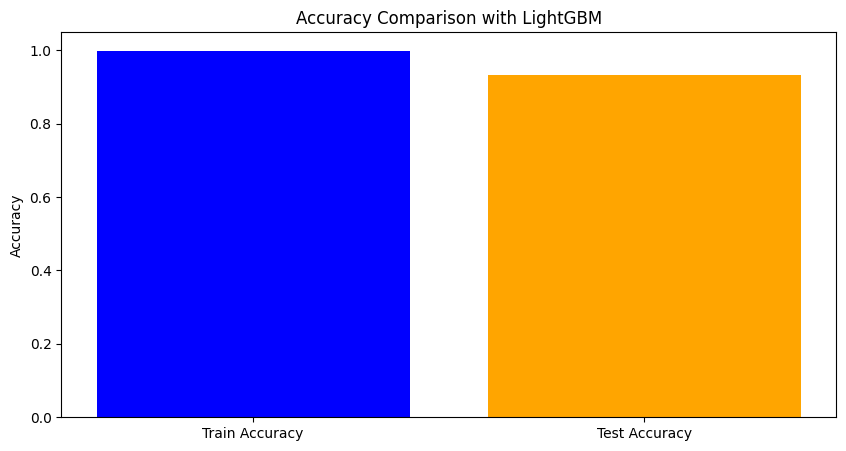

In [2]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import transforms, datasets, models
import torch.nn as nn

# Paths for train, test, and valid directories
train_dir = '/kaggle/input/save-skin/SAVE/train'
test_dir = '/kaggle/input/save-skin/SAVE/test'
valid_dir = '/kaggle/input/save-skin/SAVE/valid'

# Data preprocessing
transform = transforms.Compose([
    transforms.Resize((640, 640)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform)
valid_dataset = datasets.ImageFolder(valid_dir, transform=transform)
test_dataset = datasets.ImageFolder(test_dir, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = torch.utils.data.DataLoader(valid_dataset, batch_size=32, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

# Using ResNet34 for feature extraction
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet34 = models.resnet34(pretrained=True)
resnet34.fc = nn.Identity()  # Remove the final classification layer
resnet34 = resnet34.to(device)

# Feature extraction function
def extract_features(loader):
    resnet34.eval()
    features = []
    labels = []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = resnet34(inputs)
            features.append(outputs.cpu().numpy())
            labels.append(targets.numpy())
    return np.vstack(features), np.hstack(labels)

train_features, train_labels = extract_features(train_loader)
valid_features, valid_labels = extract_features(valid_loader)
test_features, test_labels = extract_features(test_loader)

# Train LightGBM classifier
lgb_train = lgb.Dataset(train_features, label=train_labels)
lgb_valid = lgb.Dataset(valid_features, label=valid_labels, reference=lgb_train)

params = {
    'objective': 'multiclass',
    'num_class': len(train_dataset.classes),  # Number of classes
    'boosting_type': 'gbdt',
    'metric': 'multi_logloss',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'max_depth': -1,
    'verbose': -1,
    'seed': 42
}

print("Training LightGBM model...")


# Move early stopping to the `lgb.train` workflow
gbm = lgb.train(
    params,
    lgb_train,
    valid_sets=[lgb_train, lgb_valid],
    num_boost_round=100,
    valid_names=['train', 'valid'],  # For clarity in logs
    callbacks=[lgb.early_stopping(stopping_rounds=10)]  # Use LightGBM's built-in callback
)

# Save the model
joblib.dump(gbm, 'best_lightgbm_model.pkl')

# Evaluate on test set
test_preds = gbm.predict(test_features)
test_preds_labels = np.argmax(test_preds, axis=1)

print("Classification Report:")
print(classification_report(test_labels, test_preds_labels))
print("Confusion Matrix:")
print(confusion_matrix(test_labels, test_preds_labels))

# Accuracy comparison
train_preds = gbm.predict(train_features)
train_preds_labels = np.argmax(train_preds, axis=1)
train_accuracy = accuracy_score(train_labels, train_preds_labels)
test_accuracy = accuracy_score(test_labels, test_preds_labels)

print(f"Train Accuracy: {train_accuracy:.2f}")
print(f"Test Accuracy: {test_accuracy:.2f}")

# Plot accuracy comparison
accuracies = [train_accuracy, test_accuracy]

plt.figure(figsize=(10, 5))
plt.bar(['Train Accuracy', 'Test Accuracy'], accuracies, color=['blue', 'orange'])
plt.title("Accuracy Comparison with LightGBM")
plt.ylabel("Accuracy")
plt.show()
